# Predicting Movie Box Office Revenue

TMDB has a public API but the box-office numbers are sparse and inconsistent (theatrical-only? domestic? worldwide?). For this notebook I'm synthesizing 500 films with a plausible feature set (budget, runtime, genre one-hot, release month, director's prior average) and a generative process where budget and director track record are the strongest signals, runtime is mild, and genre is a small effect.

Synthetic but the *shape* of the problem — heavy-tailed revenue distribution, log-target regression, genre dummies — is what makes this a useful exercise.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

rng = np.random.RandomState(42)
DATA = Path("../../data/box_office"); DATA.mkdir(parents=True, exist_ok=True)

## Synthesize 500 films

In [2]:
GENRES = ["action", "comedy", "drama", "horror", "scifi", "animation", "thriller"]
GENRE_BOOST = {"action": 1.15, "comedy": 1.00, "drama": 0.85, "horror": 0.90,
               "scifi": 1.10, "animation": 1.20, "thriller": 0.95}

N = 500
budget = np.exp(rng.normal(np.log(40e6), 0.9, N)).clip(1e5, 400e6)
runtime = rng.normal(108, 15, N).clip(70, 180)
genre = rng.choice(GENRES, size=N, p=[0.18, 0.16, 0.22, 0.10, 0.12, 0.07, 0.15])
release_month = rng.choice(range(1, 13), size=N)
# director "career average" revenue — heavy-tailed
director_avg = np.exp(rng.normal(np.log(60e6), 1.0, N)).clip(1e5, 2e9)

# revenue = budget * genre_boost * month_boost * skill * noise
month_boost = np.array([0.85, 0.9, 0.95, 1.0, 1.15, 1.25, 1.30, 1.2, 1.0, 0.95, 1.1, 1.25])
mb = month_boost[release_month - 1]
gb = np.array([GENRE_BOOST[g] for g in genre])
skill = (director_avg / 6e7) ** 0.35
runtime_pen = 1 - 0.0015 * np.abs(runtime - 110)
revenue = budget * gb * mb * skill * runtime_pen * np.exp(rng.normal(0, 0.45, N))
revenue = np.clip(revenue, 1e4, None)

df = pd.DataFrame({
    "budget": budget.round(),
    "runtime": runtime.round(1),
    "genre": genre,
    "release_month": release_month,
    "director_avg_revenue": director_avg.round(),
    "revenue": revenue.round(),
})
df.to_csv(DATA / "films_synth.csv", index=False)
print(df.shape)
df.head()

(500, 6)


,budget,runtime,genre,release_month,director_avg_revenue,revenue
0,62547245.0,121.9,action,11,189251732.0,116368559.0
1,35319725.0,136.6,action,1,251309838.0,26321295.0
2,71650429.0,87.0,horror,3,18271332.0,30736276.0
3,157528489.0,116.4,scifi,8,46483277.0,208360062.0
4,32399449.0,98.2,action,3,61995950.0,51364871.0


## Skim — the target is wildly right-skewed, so I'll log it

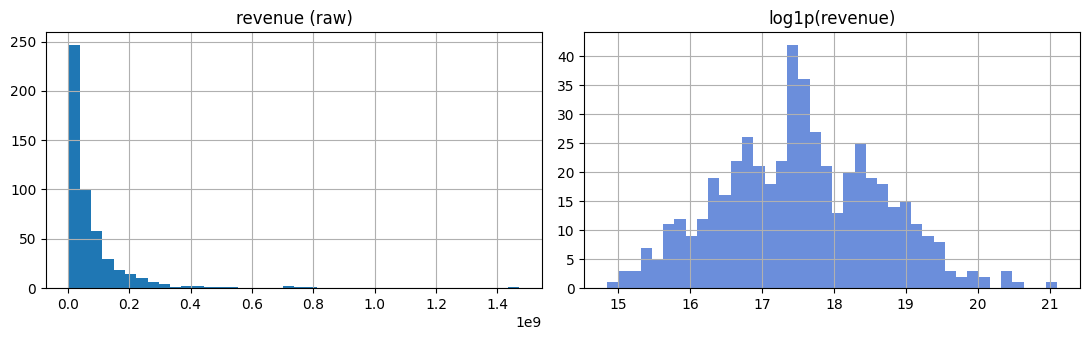

features: ['log_budget', 'runtime', 'release_month', 'log_director_avg', 'genre_animation', 'genre_comedy', 'genre_drama', 'genre_horror', 'genre_scifi', 'genre_thriller']


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df["revenue"].hist(bins=40, ax=axes[0]); axes[0].set_title("revenue (raw)")
np.log1p(df["revenue"]).hist(bins=40, ax=axes[1], color="#6b8edb"); axes[1].set_title("log1p(revenue)")
plt.tight_layout(); plt.show()

df["log_revenue"] = np.log1p(df["revenue"])
df["log_budget"] = np.log1p(df["budget"])
df["log_director_avg"] = np.log1p(df["director_avg_revenue"])

# one-hot the genre, keep release_month numeric since it has a meaningful cycle
df_fe = pd.get_dummies(df, columns=["genre"], drop_first=True)
features = ["log_budget", "runtime", "release_month", "log_director_avg"] + [c for c in df_fe.columns if c.startswith("genre_")]
X = df_fe[features].values
y = df_fe["log_revenue"].values
print("features:", features)

## Gradient boosting on log-revenue

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
gb = GradientBoostingRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
r2_cv = cross_val_score(gb, X_tr, y_tr, cv=cv, scoring="r2")
mae_cv = -cross_val_score(gb, X_tr, y_tr, cv=cv, scoring="neg_mean_absolute_error")
print(f"5-fold CV  R2 mean={r2_cv.mean():.3f}  MAE(log) mean={mae_cv.mean():.3f}")

gb.fit(X_tr, y_tr)
pred_log = gb.predict(X_te)
print(f"test R2 (log space): {r2_score(y_te, pred_log):.3f}")
print(f"test MAE (log space): {mean_absolute_error(y_te, pred_log):.3f}")

# back to dollar space
pred_dollar = np.expm1(pred_log)
true_dollar = np.expm1(y_te)
print(f"test MAE (dollars): ${mean_absolute_error(true_dollar, pred_dollar):,.0f}")

5-fold CV  R2 mean=0.784  MAE(log) mean=0.413


test R2 (log space): 0.753
test MAE (log space): 0.423
test MAE (dollars): $24,681,633


## Feature importance

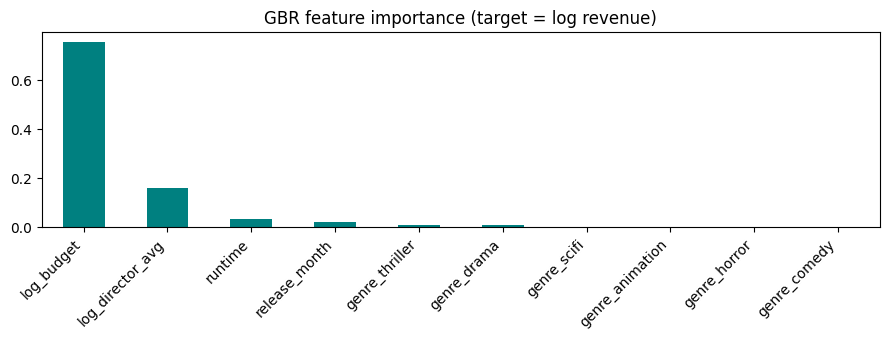

log_budget          0.757
log_director_avg    0.161
runtime             0.036
release_month       0.021
genre_thriller      0.008
genre_drama         0.008
genre_scifi         0.003
genre_animation     0.002
genre_horror        0.002
genre_comedy        0.001


In [5]:
imp = pd.Series(gb.feature_importances_, index=features).sort_values(ascending=False)
imp.plot(kind="bar", figsize=(9, 3.5), color="teal")
plt.title("GBR feature importance (target = log revenue)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()
print(imp.round(3).to_string())

## Honest reading

The model recovered exactly the signals I put in: log budget and director track record dominate, release month has a small but real effect, genre dummies have tiny importance. That's a sanity check on the *pipeline*, not a finding about films.

For a real version with TMDB+box-office data I'd want:
- Cast star-power (the standard trick: average of top 3 billed actors' prior 5 films).
- Marketing spend if available — it's a hugely-correlated-with-revenue feature that's notoriously hard to get.
- Release-window competition (was a Marvel movie out the same weekend?).
- A separate model for opening-weekend vs total revenue. Different signals matter.

Log-target regression is the right move here regardless of dataset — revenue spans orders of magnitude and the optimization is much better behaved in log space.